# Target trials emulation across stroke severity and treatment

## Introduction

### Aims

This notebook uses target trial emulation on routinely collected stroke registry data (SSNAP, England and Wales, admissions 2020-2025) to estimate the effect of thrombolysis (IVT) and thrombectomy (MT) on patient outcomes at discharge. It addresses three questions: how the association between treatment and outcome varies with stroke severity; how it varies with the type and timing of treatment; and whether the pattern is consistent across outcomes. Treatment is broken down by:

* **Stroke severity:** NIHSS bands 1–5, 6–10, 11–15, 16–20 and 21–25.
* **Treatment timing:** early (≤ 270 minutes from stroke onset) or late (> 270 minutes, or onset time not known).
* **Treatment combination:** IVT alone, MT alone, or IVT + MT.
* **Perfusion imaging:** for late treatment, with or without perfusion imaging.

Each combination is defined in `trial_groups.csv` and analysed as its own emulated trial, comparing patients who received that treatment strategy with matched patients who received no reperfusion treatment.

### Target trial

| Component | Target trial | Emulation in this notebook |
|---|---|---|
| Eligibility | Adults with ischaemic stroke and an arrival NIHSS in the trial's band | SSNAP patients with infarction, arrival NIHSS in the band and a recorded discharge mRS; patients given IVT after MT are excluded |
| Treatment strategies | The trial's reperfusion strategy versus no reperfusion treatment | Treated: patients whose recorded treatment exactly matches the group's pattern. Untreated: patients in the band with neither IVT nor MT |
| Assignment | Random allocation | 1:1 exact matching on prior mRS, NIHSS band, age band, anticoagulant use for AF, and AF diagnosis |
| Time zero | Stroke onset | Stroke onset. Treatment times are measured from onset; treatment status is taken from treatment received during the admission |
| Follow-up | Onset to discharge or in-hospital death | Onset to discharge or in-hospital death |
| Outcomes | Good outcome, in-hospital death, discharge mRS, length of stay, discharge destination | From SSNAP discharge data |
| Causal contrast | Strategy versus no reperfusion treatment | Effect of treatment in the treated, from matched pairs |
| Analysis | Comparison between randomised arms | Paired comparison within matched pairs, with Holm adjustment across trial groups |

### Methods

1. **Population.** Ischaemic stroke (infarction) patients with a recorded discharge mRS. Patients recorded as receiving thrombolysis after thrombectomy are excluded. Patients with an arrival NIHSS of 0 or above 25 fall outside all bands and are not in any trial. The most severe band is capped at NIHSS 25 to avoid the very worst strokes, which carry a high risk of death and where decisions not to attempt reperfusion treatment are most likely to be influenced by that poor prognosis.
2. **Treatment groups.** Treatment times are measured from stroke onset. IVT and MT are classed as early if given within `CUTOFF` (270 minutes) of onset and late otherwise. When onset time is not known, treatment is classed as late. Each trial group's *treated* arm is the patients in its NIHSS band with exactly its treatment pattern. For groups with late treatment, the perfusion-imaging pattern must also match. Early-only groups include patients with or without perfusion imaging.
3. **Controls.** The *untreated* arm is patients in the same NIHSS band who received neither IVT nor MT.
4. **Matching.** Each treated patient is matched 1:1, without replacement, to an untreated patient with identical values of `MATCHING_FEATURES`: prior disability, NIHSS band, age band, anticoagulant use for AF, and AF diagnosis. Treated patients without a match are dropped, and the percentage matched is reported for each group. Untreated patients may serve as controls in more than one group.
5. **Baseline characteristics.** A baseline table is produced for each matched group. For characteristics not used in matching (arrival NIHSS within the band, sex, hypertension, diabetes, congestive heart failure) the standardised mean difference (SMD) shows the remaining imbalance.
6. **Outcomes** (all at discharge, in the order used in the paper).
    * Good outcome: discharge mRS ≤ `MRS_TARGET` or no worse than pre-stroke (binary).
    * In-hospital death (binary).
    * Discharge mRS (continuous).
    * Length of stay (continuous).
    * Discharge destination (categorical).
7. **Analysis.** Because the data are matched pairs, paired methods are used. Pairs missing an outcome for either patient are dropped; missing data are not imputed.
    * Binary outcomes: McNemar's test, risk difference with 95% CI and matched-pair odds ratio.
    * Continuous outcomes: Wilcoxon signed-rank test (paired t-test also calculated) and mean difference with 95% CI.
    * Categorical outcomes: Stuart–Maxwell test.

    Holm-adjusted p-values account for testing across trial groups within each outcome. Results estimate the effect of treatment in the treated. Each trial group has its own controls, so treatment strategies are not formally compared with each other.
8. **Outputs.** The baseline table, and a statistics table (CSV) and chart (PNG) for each outcome, are saved to `output/` using the `prefix` set at the top of the notebook.

### Limitations

* **Residual confounding.** Matching is on a small set of baseline features. Untreated patients may differ from treated patients in ways not captured, for example arrival time, contraindications, large-vessel occlusion, or other reasons for not being treated.
* **Severity within bands.** Matching is on NIHSS band, not exact score. The baseline table shows that treated patients have higher NIHSS than controls in the 1–5 band (works against treatment). In the 21–25 band, arrival NIHSS is balanced between arms.
* **Most severe strokes not included.** Patients with an arrival NIHSS above 25 are not in any trial, so the results do not describe the most severe strokes.
* **Timing of treatment.** Treatment status uses treatment received at any point in the admission, so patients who die or deteriorate before they can be treated fall in the untreated arm (immortal time bias, favours treatment). Late groups include treatment with unknown onset time.
* **Outcomes at discharge.** Outcomes are measured at discharge, not at 90 days as in most trials.

Estimates should therefore be read as associations rather than causal effects.

In [1]:
import numpy as np
import pandas as pd

## Parameters

* `prefix`: start of the file name for all saved outputs.
* `MRS_TARGET`: a good outcome is a discharge mRS at or below this value (2), or a discharge mRS no worse than before the stroke.
* `CUTOFF`: treatment within this many minutes of stroke onset (270 minutes, 4.5 hours) is classed as early. This is the time window within which the benefit of IVT is established.

In [2]:
prefix = "all_ischaemic_stroke_target_trials"
MRS_TARGET = 2
CUTOFF = 270

## Define fields

* `DESCRIPTIVE_FEATURES`: patient characteristics on arrival, used to describe the matched groups in the baseline table.
* `TREATMENT_FEATURES`: treatment times and the early/late treatment flags that define each trial group.
* `MATCHING_FEATURES`: the five variables on which treated and untreated patients are exactly matched. They describe the patient before or at admission and are related to both the likelihood of treatment and outcome. Age is recorded in 5-year bands (the midpoint of the band is used), and `any_afib_diagnosis` includes AF newly diagnosed on admission.
* `OUTCOME_FEATURES`: the five discharge outcomes.

In [3]:
DESCRIPTIVE_FEATURES = [
    'male',
    'prior_disability',
    'stroke_severity',
    'age',
    'congestive_heart_failure',
    'hypertension',
    'diabetes',
    'afib_anticoagulant',
    'any_afib_diagnosis',
]

TREATMENT_FEATURES = [
    'perfusion_imaging_used',
    'onset_to_thrombolysis_time',
    'onset_to_thrombectomy_time',
    'arrival_to_thrombolysis_time',
    'arrival_to_thrombectomy_time',
    'early_ivt',
    'early_mt',
    'late_ivt',
    'late_mt',
]

MATCHING_FEATURES = [
    'prior_disability',
    'stroke_severity_band',
    'age',
    'afib_anticoagulant',
    'any_afib_diagnosis',
]

OUTCOME_FEATURES = [
    'outcome_target',
    'discharge_disability',
    'discharge_destination',
    'death',
    'length_of_stay',
]

ALL_FEATURES = list(set(
    DESCRIPTIVE_FEATURES + TREATMENT_FEATURES + MATCHING_FEATURES + OUTCOME_FEATURES))


## Load and filter data

The cleaned SSNAP data are loaded (see `data/sam3/clean_data.ipynb` for cleaning). The study population is then defined:

1. Keep patients with a recorded discharge mRS.
2. Keep ischaemic stroke (infarction) only.
3. Remove patients recorded as receiving IVT after MT.

Derived variables:

* **Early and late treatment.** Treatment times are from stroke onset (time zero). `early_ivt` and `early_mt` are 1 if treatment was given within `CUTOFF` minutes of onset. `late_ivt` and `late_mt` are 1 if treatment was given after `CUTOFF`, or if the onset-to-treatment time is missing because onset time is not known.
* **Stroke severity band.** Arrival NIHSS is grouped into the bands in `trial_groups.csv`. NIHSS 0 and NIHSS above 25 fall outside all bands, so those patients are not in any trial.
* **Good outcome.** `outcome_target` is 1 if discharge mRS ≤ `MRS_TARGET` or discharge mRS is no worse than pre-stroke mRS.

In [4]:
data = pd.read_csv("../data/sam3/cleaned_data.csv", low_memory=False)

# Calculate onset_to_scan
data["onset_to_scan_time"] = data["onset_to_arrival_time"] - data["arrival_to_scan_time"]

print(f"Initial data shape: {data.shape}")

# Remove rows with missing discharge disability
data = data.dropna(subset=["discharge_disability"])

# Keep only infarction cases
data = data[data["infarction"] == 1]

thrombolysis_after_thrombectomy = (
    data["onset_to_thrombolysis_time"] > data["onset_to_thrombectomy_time"]
)
data = data[~thrombolysis_after_thrombectomy]

# add 'early_ivt' if 'thrombolysosis' is 1 and 'onset_to_thrombolysis_time' <= CUTOFF
data["early_ivt"] = (
    (data["thrombolysis"] == 1) & (data["onset_to_thrombolysis_time"] <= CUTOFF)
).astype(int)

# Add 'late_ivt' if 'thrombolysosis' is 1 and 'onset_to_thrombolysis_time' is empty or > CUTOFF
data["late_ivt"] = (
    (data["thrombolysis"] == 1)
    & (
        (data["onset_to_thrombolysis_time"].isna())
        | (data["onset_to_thrombolysis_time"] > CUTOFF)
    )
).astype(int)

# Add 'early_mt' if 'thrombectomy' is 1 and 'onset_to_thrombectomy_time' <= CUTOFF
data["early_mt"] = (
    (data["thrombectomy"] == 1) & (data["onset_to_thrombectomy_time"] <= CUTOFF)
).astype(int)

# Add 'late_mt' if 'thrombectomy' is 1 and 'onset_to_thrombectomy_time' is empty or > CUTOFF
data["late_mt"] = (
    (data["thrombectomy"] == 1)
    & (
        (data["onset_to_thrombectomy_time"].isna())
        | (data["onset_to_thrombectomy_time"] > CUTOFF)
    )
).astype(int)


# Add stroke_severity_band, using the NIHSS bands defined in trial_groups.csv
# (1-5, 6-10, 11-15, 16-20, 21-25). NIHSS outside all bands (0, or above 25) -> NaN.
severity_bands = (
    pd.read_csv("./trial_groups.csv")[["NIHSS Min", "NIHSS Max"]]
    .drop_duplicates()
    .sort_values("NIHSS Min")
    .reset_index(drop=True)
)
# Bands must be contiguous, with no gaps or overlaps
assert (
    severity_bands["NIHSS Min"].iloc[1:].values
    == severity_bands["NIHSS Max"].iloc[:-1].values + 1
).all(), "NIHSS bands in trial_groups.csv are not contiguous"

severity_bins = [severity_bands["NIHSS Min"].iloc[0] - 1] + severity_bands["NIHSS Max"].tolist()
severity_labels = [f"{lo}-{hi}" for lo, hi in severity_bands.itertuples(index=False)]

data["stroke_severity_band"] = pd.cut(
    pd.to_numeric(data["stroke_severity"], errors="coerce"),
    bins=severity_bins,
    labels=severity_labels,
    right=True,  # (0, 5] -> "1-5", (5, 10] -> "6-10", ...
)

# Add outcome variable: mRS <= MRS_TARGET or return to pre-stroke mRS
data["outcome_target"] = (
    (data["discharge_disability"] <= MRS_TARGET)
    | (data["discharge_disability"] <= data["prior_disability"])).astype(int)

# Select features 
data = data[ALL_FEATURES]


print(f"Final data shape: {data.shape}")

Initial data shape: (452863, 74)
Final data shape: (384334, 24)


## Trial groups

Each row of `trial_groups.csv` defines one emulated trial: an NIHSS band, a pattern of early and late IVT and MT, and (for groups with late treatment) whether perfusion imaging was used. There are 39 groups: three IVT-only groups in each of the NIHSS 1–5 and 6–10 bands, and eleven groups (IVT only, MT only, and IVT + MT) in each of the NIHSS 11–15, 16–20 and 21–25 bands. The most severe band is capped at NIHSS 25 to avoid the very worst strokes, which carry a high risk of death and where decisions not to attempt reperfusion treatment are most likely to be influenced by that poor prognosis.

Group names give the treatment and timing, with "(perfusion)" marking late treatment with perfusion imaging; "MT late" without "(perfusion)" means no perfusion imaging was recorded.

Perfusion imaging is recorded in the thrombectomy section of SSNAP, so the "IVT late (perfusion)" groups are expected to be empty.

In [5]:
# Import treatment groups
treatment_groups_df = pd.read_csv("./trial_groups.csv", low_memory=False)
display(treatment_groups_df)

,Group ID,Group name,NIHSS Min,NIHSS Max,IVT<= 270,IVT>270,MT<=270,MT>270,Perfusion imaging
0,1,NIHSS 1-5: IVT early,1,5,1,0,0,0,0
1,2,NIHSS 1-5: IVT late,1,5,0,1,0,0,0
2,3,NIHSS 1-5: IVT late (perfusion),1,5,0,1,0,0,1
3,4,NIHSS 6-10: IVT early,6,10,1,0,0,0,0
4,5,NIHSS 6-10: IVT late,6,10,0,1,0,0,0
5,6,NIHSS 6-10: IVT late (perfusion),6,10,0,1,0,0,1
6,7,NIHSS 11-15: IVT early,11,15,1,0,0,0,0
7,8,NIHSS 11-15: IVT late,11,15,0,1,0,0,0
8,9,NIHSS 11-15: IVT late (perfusion),11,15,0,1,0,0,1
9,10,NIHSS 11-15: MT early,11,15,0,0,1,0,0


## Match treated and untreated patients

For each treatment group:

* **Treated** patients are in the group's NIHSS band and have exactly the group's treatment pattern (early/late IVT, early/late MT).
* **Untreated** patients are in the same NIHSS band and had neither IVT nor MT.

Each treated patient is matched 1:1, without replacement, to an untreated patient with identical `MATCHING_FEATURES`. Treated patients without a match (including those missing any matching feature) are dropped, and the percentage of treated patients matched is recorded for each group. The same untreated patient may be used as a control in different groups.

Exact matching is possible because the pool of untreated patients is large. Because controls are chosen to resemble the treated patients, comparisons estimate the average effect of treatment in the treated: the effect in patients like those who actually received each treatment. A fixed random seed makes the matching reproducible.

In [6]:
RANDOM_SEED = 42

# Treatment columns in trial_groups.csv -> treatment flags in data
TREATMENT_FLAG_COLUMNS = {
    "IVT<= 270": "early_ivt",
    "IVT>270": "late_ivt",
    "MT<=270": "early_mt",
    "MT>270": "late_mt",
}
TREATMENT_FLAGS = list(TREATMENT_FLAG_COLUMNS.values())

# Columns defining each group's treated pattern: treatment flags + perfusion imaging.
# Perfusion imaging is not a treatment, so it does not restrict the untreated pool.
GROUP_PATTERN_COLUMNS = {**TREATMENT_FLAG_COLUMNS, "Perfusion imaging": "perfusion_imaging_used"}

# Untreated: no thrombolysis or thrombectomy at any time
untreated = (data[TREATMENT_FLAGS] == 0).all(axis=1)

# Patients missing any matching feature cannot be exactly matched
complete_matching_data = data[MATCHING_FEATURES].notna().all(axis=1)


def exact_match(treated, controls, features, rng):
    """1:1 exact matching without replacement.

    Within each combination of `features`, treated and untreated patients are
    put in random order and paired off. Treated patients left over when a
    combination has too few untreated patients are unmatched.

    Returns a DataFrame of (treated_id, control_id) index pairs.
    """
    def ranked(df, id_name):
        df = df[features].iloc[rng.permutation(len(df))].copy()
        df["_rank"] = df.groupby(features, observed=True).cumcount()
        return df.rename_axis(id_name).reset_index()

    pairs = ranked(treated, "treated_id").merge(
        ranked(controls, "control_id"), on=features + ["_rank"], how="inner"
    )
    return pairs[["treated_id", "control_id"]]


rng = np.random.default_rng(RANDOM_SEED)
matched_groups = []
summary_rows = []

for _, group in treatment_groups_df.iterrows():
    summary = {"group_id": group["Group ID"], "group_name": group["Group name"], "note": ""}

    band = f"{group['NIHSS Min']}-{group['NIHSS Max']}"
    in_band = data["stroke_severity_band"] == band

    # Treated: in band, with exactly this group's treatment and perfusion pattern.
    # Perfusion imaging only distinguishes late-treatment groups; early-only groups
    # include patients with or without perfusion imaging.
    has_late_treatment = group["IVT>270"] == 1 or group["MT>270"] == 1
    is_treated = in_band.copy()
    for sheet_col, data_col in GROUP_PATTERN_COLUMNS.items():
        if sheet_col == "Perfusion imaging" and not has_late_treatment:
            continue
        is_treated &= data[data_col] == group[sheet_col]

    treated = data[is_treated]
    controls = data[in_band & untreated & complete_matching_data]
    pairs = exact_match(
        data[is_treated & complete_matching_data], controls, MATCHING_FEATURES, rng
    )

    n_treated = len(treated)
    summary.update({
        "n_treated": n_treated,
        "n_treated_missing_matching_data": int((~complete_matching_data[is_treated]).sum()),
        "n_untreated_pool": len(controls),
        "n_matched": len(pairs),
        "pct_treated_matched": round(100 * len(pairs) / n_treated, 1) if n_treated else np.nan,
    })
    summary_rows.append(summary)

    # Build matched treated + untreated rows, linked by pair_id
    pair_id = np.arange(len(pairs))
    group_matched = pd.concat([
        data.loc[pairs["treated_id"]].assign(treated=1, pair_id=pair_id),
        data.loc[pairs["control_id"]].assign(treated=0, pair_id=pair_id),
    ]).rename_axis("patient_id").reset_index()
    group_matched.insert(0, "group_id", group["Group ID"])
    group_matched.insert(1, "group_name", group["Group name"])
    matched_groups.append(group_matched)

matched_data = pd.concat(matched_groups, ignore_index=True)
match_summary = pd.DataFrame(summary_rows).set_index("group_id")

print(f"Matched data shape: {matched_data.shape}")
display(match_summary)

Matched data shape: (109274, 29)


,group_name,note,n_treated,n_treated_missing_matching_data,n_untreated_pool,n_matched,pct_treated_matched
group_id,,,,,,,
1,NIHSS 1-5: IVT early,,12954,0,186476,12954,100.0
2,NIHSS 1-5: IVT late,,1441,0,186476,1440,99.9
3,NIHSS 1-5: IVT late (perfusion),,0,0,186476,0,NaN
4,NIHSS 6-10: IVT early,,13620,0,55383,13618,100.0
5,NIHSS 6-10: IVT late,,1478,0,55383,1478,100.0
6,NIHSS 6-10: IVT late (perfusion),,0,0,55383,0,NaN
7,NIHSS 11-15: IVT early,,6289,0,20318,6277,99.8
8,NIHSS 11-15: IVT late,,643,0,20318,643,100.0
9,NIHSS 11-15: IVT late (perfusion),,0,0,20318,0,NaN


## Baseline characteristics

Baseline characteristics of the matched treated and untreated patients in each trial group. The matching variables (age, prior disability, AF diagnosis and anticoagulant use) are identical between arms by design. For characteristics not used in matching (arrival NIHSS within the band, sex, hypertension, diabetes and congestive heart failure), the standardised mean difference (SMD, treated minus untreated) shows the remaining imbalance. Onset-to-treatment times are given for the treated arm. The table is saved to `output/`.

In [7]:
# Baseline characteristics of matched treated and untreated patients.
# Saves output/<prefix>_baseline_characteristics.csv, one row per trial group.
import os

BASELINE_DIR = "./output"
os.makedirs(BASELINE_DIR, exist_ok=True)

# Binary characteristics (reported as % of patients). Variables not in the data are skipped.
BASELINE_BINARY = [
    "male", "any_afib_diagnosis", "afib_anticoagulant",
    "hypertension", "diabetes", "congestive_heart_failure",
]
# Characteristics not used in matching: standardised mean difference (SMD) is reported
BASELINE_UNMATCHED = ["stroke_severity", "male", "hypertension", "diabetes", "congestive_heart_failure"]


def standardised_mean_difference(treated, untreated):
    """SMD (treated minus untreated) using the pooled standard deviation."""
    t = pd.to_numeric(treated, errors="coerce").dropna().astype(float)
    u = pd.to_numeric(untreated, errors="coerce").dropna().astype(float)
    if len(t) < 2 or len(u) < 2:
        return np.nan
    pooled_sd = np.sqrt((t.var(ddof=1) + u.var(ddof=1)) / 2)
    return (t.mean() - u.mean()) / pooled_sd if pooled_sd > 0 else 0.0


baseline_rows = []
for (group_id, group_name), group_data in matched_data.groupby(["group_id", "group_name"]):
    arms = {"treated": group_data[group_data["treated"] == 1],
            "untreated": group_data[group_data["treated"] == 0]}
    row = {"group_id": group_id, "group_name": group_name, "n_pairs": len(arms["treated"])}

    for arm, d in arms.items():
        age = pd.to_numeric(d["age"], errors="coerce")
        mrs = pd.to_numeric(d["prior_disability"], errors="coerce")
        nihss = pd.to_numeric(d["stroke_severity"], errors="coerce")
        row[f"{arm}_age_mean"] = age.mean()
        row[f"{arm}_age_sd"] = age.std()
        row[f"{arm}_prior_mrs_mean"] = mrs.mean()
        row[f"{arm}_prior_mrs_sd"] = mrs.std()
        row[f"{arm}_prior_mrs_0_to_2_pct"] = 100 * (mrs <= 2).mean()
        row[f"{arm}_nihss_mean"] = nihss.mean()
        row[f"{arm}_nihss_median"] = nihss.median()
        row[f"{arm}_nihss_q1"] = nihss.quantile(0.25)
        row[f"{arm}_nihss_q3"] = nihss.quantile(0.75)
        for var in BASELINE_BINARY:
            if var in d.columns:
                row[f"{arm}_{var}_pct"] = 100 * pd.to_numeric(d[var], errors="coerce").mean()

    for var in BASELINE_UNMATCHED:
        if var in group_data.columns:
            row[f"smd_{var}"] = standardised_mean_difference(arms["treated"][var], arms["untreated"][var])

    # Treatment times (treated arm only), minutes from onset
    t = arms["treated"]
    for label, time_col, flags in [("ivt", "onset_to_thrombolysis_time", ["early_ivt", "late_ivt"]),
                                   ("mt", "onset_to_thrombectomy_time", ["early_mt", "late_mt"])]:
        had = t[flags].sum(axis=1) > 0
        times = pd.to_numeric(t.loc[had, time_col], errors="coerce")
        row[f"treated_n_{label}"] = int(had.sum())
        row[f"treated_onset_to_{label}_median"] = times.median()
        row[f"treated_onset_to_{label}_q1"] = times.quantile(0.25)
        row[f"treated_onset_to_{label}_q3"] = times.quantile(0.75)
        row[f"treated_onset_to_{label}_unknown_pct"] = 100 * times.isna().mean() if had.any() else np.nan

    baseline_rows.append(row)

baseline = pd.DataFrame(baseline_rows).set_index("group_id")
baseline_path = f"{BASELINE_DIR}/{prefix}_baseline_characteristics.csv"
baseline.to_csv(baseline_path)
print(f"Saved table: {baseline_path}")
display(baseline.style.format(precision=2, na_rep="-"))

Saved table: ./output/all_ischaemic_stroke_target_trials_baseline_characteristics.csv


,group_name,n_pairs,treated_age_mean,treated_age_sd,treated_prior_mrs_mean,treated_prior_mrs_sd,treated_prior_mrs_0_to_2_pct,treated_nihss_mean,treated_nihss_median,treated_nihss_q1,treated_nihss_q3,treated_male_pct,treated_any_afib_diagnosis_pct,treated_afib_anticoagulant_pct,treated_hypertension_pct,treated_diabetes_pct,treated_congestive_heart_failure_pct,untreated_age_mean,untreated_age_sd,untreated_prior_mrs_mean,untreated_prior_mrs_sd,untreated_prior_mrs_0_to_2_pct,untreated_nihss_mean,untreated_nihss_median,untreated_nihss_q1,untreated_nihss_q3,untreated_male_pct,untreated_any_afib_diagnosis_pct,untreated_afib_anticoagulant_pct,untreated_hypertension_pct,untreated_diabetes_pct,untreated_congestive_heart_failure_pct,smd_stroke_severity,smd_male,smd_hypertension,smd_diabetes,smd_congestive_heart_failure,treated_n_ivt,treated_onset_to_ivt_median,treated_onset_to_ivt_q1,treated_onset_to_ivt_q3,treated_onset_to_ivt_unknown_pct,treated_n_mt,treated_onset_to_mt_median,treated_onset_to_mt_q1,treated_onset_to_mt_q3,treated_onset_to_mt_unknown_pct
group_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12954,70.48,13.08,0.52,0.94,93.53,3.69,4.00,3.00,5.00,61.43,12.23,2.22,51.21,19.04,3.54,70.48,13.08,0.52,0.94,93.53,2.65,2.00,2.00,4.00,58.84,12.23,2.22,54.50,24.05,3.40,0.83,0.05,-0.07,-0.12,0.01,12954,170.00,135.00,213.00,0.00,0,-,-,-,-
2,NIHSS 1-5: IVT late,1440,69.80,13.29,0.51,0.88,94.93,3.56,4.00,3.00,5.00,63.75,12.43,2.92,53.89,18.68,3.33,69.80,13.29,0.51,0.88,94.93,2.60,2.00,1.00,4.00,60.97,12.43,2.92,52.92,25.35,3.33,0.74,0.06,0.02,-0.16,0.00,1440,328.00,286.00,438.00,18.26,0,-,-,-,-
4,NIHSS 6-10: IVT early,13618,72.23,13.28,0.78,1.15,87.37,7.63,7.00,6.00,9.00,57.48,15.84,2.82,53.60,21.51,4.43,72.23,13.28,0.78,1.15,87.37,7.39,7.00,6.00,8.00,55.77,15.84,2.82,55.54,26.63,4.24,0.18,0.03,-0.04,-0.12,0.01,13618,165.00,130.00,206.00,0.00,0,-,-,-,-
5,NIHSS 6-10: IVT late,1478,72.41,13.19,0.79,1.12,88.84,7.58,7.00,6.00,9.00,57.98,15.29,3.38,55.68,23.55,4.33,72.41,13.19,0.79,1.12,88.84,7.46,7.00,6.00,9.00,52.84,15.29,3.38,56.50,27.13,4.19,0.09,0.10,-0.02,-0.08,0.01,1478,344.00,290.00,480.00,20.64,0,-,-,-,-
7,NIHSS 11-15: IVT early,6277,74.20,13.39,1.02,1.31,81.33,12.76,13.00,11.00,14.00,53.80,21.25,3.31,54.42,22.32,4.95,74.20,13.39,1.02,1.31,81.33,12.72,13.00,11.00,14.00,49.83,21.25,3.31,55.44,24.06,5.27,0.03,0.08,-0.02,-0.04,-0.01,6277,159.00,125.00,200.00,0.00,0,-,-,-,-
8,NIHSS 11-15: IVT late,643,74.06,12.55,1.02,1.30,83.51,12.78,13.00,12.00,14.00,51.94,20.53,4.04,56.14,24.42,6.84,74.06,12.55,1.02,1.30,83.51,12.74,13.00,11.00,14.00,49.46,20.53,4.04,56.14,23.17,6.22,0.03,0.05,0.00,0.03,0.03,643,337.00,287.00,459.00,21.46,0,-,-,-,-
10,NIHSS 11-15: MT early,281,71.17,13.39,0.69,0.89,95.37,13.09,13.00,12.00,14.00,55.16,51.96,49.11,47.69,18.86,8.54,71.17,13.39,0.69,0.89,95.37,12.64,12.00,11.00,14.00,57.30,51.96,49.11,53.02,27.05,6.05,0.33,-0.04,-0.11,-0.20,0.10,0,-,-,-,-,281,212.00,184.00,243.00,0.00
11,NIHSS 11-15: MT late,944,69.92,14.29,0.56,0.80,97.46,13.03,13.00,12.00,14.00,52.44,36.65,26.80,48.73,17.06,7.10,69.92,14.29,0.56,0.80,97.46,12.81,13.00,12.00,14.00,56.67,36.65,26.80,52.54,23.20,6.89,0.16,-0.09,-0.08,-0.15,0.01,0,-,-,-,-,944,509.50,357.75,798.50,13.56
12,NIHSS 11-15: MT late (perfusion),426,71.40,13.22,0.56,0.82,96.71,13.04,13.00,12.00,14.00,51.88,36.38,24.88,56.34,14.32,6.57,71.40,13.22,0.56,0.82,96.71,12.76,13.00,12.00,14.00,55.40,36.38,24.88,55.63,24.41,7.04,0.20,-0.07,0.01,-0.26,-0.02,0,-,-,-,-,426,616.00,435.50,990.00,22.54


## Target trials

Each treatment group is analysed as its own emulated trial, comparing matched treated patients with their matched untreated controls. This estimates the effect of treatment in the treated. Pairs where either patient is missing the outcome are dropped. Because the data are matched pairs, paired methods are used:

* **Binary outcomes:** percentage in each arm, difference in percentage points with 95% CI, matched-pair odds ratio (discordant pairs) with 95% CI, McNemar's test.
* **Continuous outcomes:** mean, SD, median and IQR in each arm, mean difference with 95% CI, Wilcoxon signed-rank test (`p_value`) and paired t-test (`p_value_paired_t`).
* **Categorical outcomes:** percentage in each category in each arm, Stuart-Maxwell test of marginal homogeneity.

Many groups are tested for each outcome, so Holm-adjusted p-values (`p_value_holm`, adjusted across groups within each outcome) are also reported. Charts mark groups with Holm-adjusted p < 0.05. Each outcome's statistics table (CSV) and chart (PNG) are saved to `output/`.

Further details:

* The 95% CI for a difference in percentages uses the mean and standard deviation of the within-pair differences (normal approximation). The 95% CI for a mean difference uses the t distribution.
* The matched-pair odds ratio is the number of pairs where only the treated patient had the outcome divided by the number where only the control had it, with a 95% CI calculated on the log scale. It is not calculated when there are no discordant pairs in one direction.
* McNemar's test uses the exact binomial version when there are fewer than 25 discordant pairs, and the continuity-corrected chi-squared version otherwise.
* Missing outcomes are not imputed.
* Each trial group has its own matched controls. Differences between trial groups are described but not formally tested.

Outcomes are analysed in the order used in the paper: good outcome, in-hospital death, discharge disability, length of stay, discharge destination.

In [8]:
import os

import matplotlib.pyplot as plt
from scipy import stats as sps
from statsmodels.stats.contingency_tables import SquareTable, mcnemar
from statsmodels.stats.multitest import multipletests

OUTPUT_DIR = "./output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Category values treated as missing in categorical outcomes
MISSING_CATEGORIES = ["missing"]

# Chart colours (reference data-viz palette, light mode)
TREATED_COLOUR = "#2a78d6"
UNTREATED_COLOUR = "#eb6834"
CATEGORY_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID_COLOUR = "#e4e3df"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID_COLOUR,
    "axes.labelcolor": TEXT_SECONDARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "text.color": TEXT_PRIMARY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "font.size": 9,
})


def paired_outcome(group_data, outcome):
    """One row per matched pair, with the outcome for the treated and untreated
    patient. Pairs where either patient is missing the outcome are dropped."""
    wide = group_data.pivot(index="pair_id", columns="treated", values=outcome)
    wide = wide.rename(columns={1: "treated", 0: "untreated"})[["treated", "untreated"]]
    return wide.dropna()


def binary_stats(wide):
    """Paired comparison of a binary outcome: difference in proportions with
    95% CI, matched-pair odds ratio and McNemar's test."""
    t = wide["treated"].astype(int)
    u = wide["untreated"].astype(int)
    n = len(wide)
    both = int(((t == 1) & (u == 1)).sum())
    treated_only = int(((t == 1) & (u == 0)).sum())
    untreated_only = int(((t == 0) & (u == 1)).sum())
    neither = n - both - treated_only - untreated_only

    diff = t - u
    rd = diff.mean() if n else np.nan
    se = diff.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan

    # Matched-pair odds ratio uses discordant pairs only
    if treated_only > 0 and untreated_only > 0:
        matched_or = treated_only / untreated_only
        log_se = np.sqrt(1 / treated_only + 1 / untreated_only)
        or_low, or_high = matched_or * np.exp(-1.96 * log_se), matched_or * np.exp(1.96 * log_se)
    else:
        matched_or = or_low = or_high = np.nan

    try:
        discordant = treated_only + untreated_only
        p = mcnemar([[both, treated_only], [untreated_only, neither]], exact=discordant < 25).pvalue
    except Exception:
        p = np.nan

    return {
        "n_pairs": n,
        "treated_events": int(t.sum()),
        "treated_pct": 100 * t.mean() if n else np.nan,
        "untreated_events": int(u.sum()),
        "untreated_pct": 100 * u.mean() if n else np.nan,
        "difference": 100 * rd,
        "ci_low": 100 * (rd - 1.96 * se),
        "ci_high": 100 * (rd + 1.96 * se),
        "matched_odds_ratio": matched_or,
        "or_ci_low": or_low,
        "or_ci_high": or_high,
        "test": "McNemar",
        "p_value": p,
    }


def continuous_stats(wide):
    """Paired comparison of a continuous outcome: mean difference with 95% CI,
    Wilcoxon signed-rank test (primary p-value) and paired t-test."""
    t = wide["treated"].astype(float)
    u = wide["untreated"].astype(float)
    n = len(wide)
    diff = t - u
    md = diff.mean() if n else np.nan

    if n > 1:
        half_width = sps.t.ppf(0.975, n - 1) * diff.std(ddof=1) / np.sqrt(n)
        ci_low, ci_high = md - half_width, md + half_width
        p_t = sps.ttest_rel(t, u).pvalue
    else:
        ci_low = ci_high = p_t = np.nan
    try:
        p_w = sps.wilcoxon(t, u).pvalue
    except ValueError:
        p_w = np.nan

    return {
        "n_pairs": n,
        "treated_mean": t.mean(),
        "treated_sd": t.std(),
        "treated_median": t.median(),
        "treated_q1": t.quantile(0.25),
        "treated_q3": t.quantile(0.75),
        "untreated_mean": u.mean(),
        "untreated_sd": u.std(),
        "untreated_median": u.median(),
        "untreated_q1": u.quantile(0.25),
        "untreated_q3": u.quantile(0.75),
        "difference": md,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "test": "Wilcoxon signed-rank",
        "p_value": p_w,
        "p_value_paired_t": p_t,
    }


def categorical_stats(wide, categories):
    """Paired comparison of a categorical outcome: percentage in each category
    and the Stuart-Maxwell test of marginal homogeneity."""
    n = len(wide)
    row = {"n_pairs": n}
    for cat in categories:
        row[f"treated_pct_{cat}"] = 100 * (wide["treated"] == cat).mean() if n else np.nan
    for cat in categories:
        row[f"untreated_pct_{cat}"] = 100 * (wide["untreated"] == cat).mean() if n else np.nan

    table = pd.crosstab(wide["treated"], wide["untreated"]).reindex(
        index=categories, columns=categories, fill_value=0
    )
    used = (table.sum(axis=0) + table.sum(axis=1)) > 0
    table = table.loc[used, used]
    try:
        p = SquareTable(table.to_numpy(), shift_zeros=False).homogeneity().pvalue
    except Exception:
        p = np.nan
    row["test"] = "Stuart-Maxwell"
    row["p_value"] = p
    return row


def format_p(p):
    if pd.isna(p):
        return "p = n/a"
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def pretty_category(cat):
    return cat.replace("_", " ").replace("ssnap", "SSNAP").replace("esd", "ESD").capitalize()


def plot_paired_results(results, treated_col, untreated_col, value_label, diff_label, title, path):
    """Two panels sharing the group axis: each arm's value, and the treated minus
    untreated difference with 95% CI (filled = Holm-adjusted p < 0.05)."""
    res = results[results["n_pairs"] > 0].iloc[::-1]  # first group at the top
    y = np.arange(len(res))
    sig = (res["p_value_holm"] < 0.05).to_numpy()

    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(13, 0.3 * len(res) + 2), sharey=True, layout="constrained"
    )

    # Panel 1: value in each arm
    ax1.hlines(y, res[untreated_col], res[treated_col], color=GRID_COLOUR, lw=2, zorder=1)
    ax1.scatter(res[untreated_col], y, s=40, color=UNTREATED_COLOUR, edgecolor=SURFACE,
                linewidth=1.5, zorder=2, label="Untreated (matched)")
    ax1.scatter(res[treated_col], y, s=40, color=TREATED_COLOUR, edgecolor=SURFACE,
                linewidth=1.5, zorder=3, label="Treated")
    ax1.set_yticks(y, res["group_name"])
    ax1.set_xlabel(value_label)
    ax1.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)

    # Panel 2: difference with 95% CI
    ax2.axvline(0, color=TEXT_SECONDARY, lw=1, zorder=1)
    ax2.hlines(y, res["ci_low"], res["ci_high"], color=TREATED_COLOUR, lw=2, zorder=2)
    ax2.scatter(res["difference"][sig], y[sig], s=40, color=TREATED_COLOUR, edgecolor=SURFACE,
                linewidth=1.5, zorder=3, label="Holm-adjusted p < 0.05")
    ax2.scatter(res["difference"][~sig], y[~sig], s=40, facecolor=SURFACE, edgecolor=TREATED_COLOUR,
                linewidth=1.5, zorder=3, label="Not significant")
    ax2.set_xlabel(diff_label)
    ax2.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)

    for ax in (ax1, ax2):
        ax.grid(axis="x", color=GRID_COLOUR, lw=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(left=False)

    fig.suptitle(title, x=0.01, ha="left", fontsize=12, color=TEXT_PRIMARY)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


def plot_categorical_results(results, categories, title, path):
    """100% stacked bars of the outcome categories for the treated and untreated
    arm of each group, with the Holm-adjusted Stuart-Maxwell p-value."""
    res = results[results["n_pairs"] > 0]
    y, labels, values = [], [], []
    for g, (_, r) in enumerate(res.iterrows()):
        for k, arm in enumerate(["treated", "untreated"]):
            y.append(-(3 * g + k))
            labels.append(f"{r['group_name']}   Treated" if arm == "treated" else "Untreated")
            values.append([r[f"{arm}_pct_{cat}"] for cat in categories])
    y = np.array(y)
    values = np.array(values)

    fig, ax = plt.subplots(figsize=(13, 0.22 * len(y) + 0.12 * len(res) + 2), layout="constrained")
    left = np.zeros(len(y))
    for j, cat in enumerate(categories):
        ax.barh(y, values[:, j], left=left, height=0.85, color=CATEGORY_COLOURS[j],
                edgecolor=SURFACE, linewidth=1, label=pretty_category(cat))
        left += values[:, j]

    for g, (_, r) in enumerate(res.iterrows()):
        ax.text(101, -(3 * g + 0.5), format_p(r["p_value_holm"]), va="center", ha="left",
                color=TEXT_SECONDARY, clip_on=False)

    ax.set_yticks(y, labels)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Patients (%)   [p-values: Stuart-Maxwell, Holm-adjusted]")
    ax.tick_params(left=False)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=len(categories), frameon=False)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, color=TEXT_PRIMARY)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


def analyse_outcome(outcome, outcome_type, title, value_label=None, diff_label=None, category_order=None):
    """Run the target trial for one outcome in every treatment group.

    outcome_type is "binary", "continuous" or "categorical". Saves a statistics
    table (CSV) and a chart (PNG) to OUTPUT_DIR and returns the statistics table.
    """
    outcome_data = matched_data[["group_id", "group_name", "pair_id", "treated", outcome]].copy()

    categories = None
    if outcome_type == "categorical":
        is_missing = outcome_data[outcome].isin(MISSING_CATEGORIES)
        outcome_data[outcome] = outcome_data[outcome].where(~is_missing)
        present = outcome_data[outcome].dropna().unique().tolist()
        categories = [c for c in (category_order or []) if c in present]
        categories += sorted(c for c in present if c not in categories)

    rows = []
    for (group_id, group_name), group_data in outcome_data.groupby(["group_id", "group_name"]):
        wide = paired_outcome(group_data, outcome)
        if outcome_type == "binary":
            group_stats = binary_stats(wide)
        elif outcome_type == "continuous":
            group_stats = continuous_stats(wide)
        elif outcome_type == "categorical":
            group_stats = categorical_stats(wide, categories)
        else:
            raise ValueError(f"Unknown outcome type: {outcome_type}")
        rows.append({"group_id": group_id, "group_name": group_name, **group_stats})

    results = pd.DataFrame(rows).set_index("group_id")

    # Holm adjustment across treatment groups, within this outcome
    results["p_value_holm"] = np.nan
    has_p = results["p_value"].notna()
    if has_p.any():
        results.loc[has_p, "p_value_holm"] = multipletests(results.loc[has_p, "p_value"], method="holm")[1]

    table_path = f"{OUTPUT_DIR}/{prefix}_{outcome}_stats.csv"
    chart_path = f"{OUTPUT_DIR}/{prefix}_{outcome}_chart.png"
    results.to_csv(table_path)

    if outcome_type == "categorical":
        plot_categorical_results(results, categories, title, chart_path)
    else:
        stat = "pct" if outcome_type == "binary" else "mean"
        if diff_label is None:
            diff_label = ("Difference, treated − untreated (percentage points)" if outcome_type == "binary"
                          else "Mean difference, treated − untreated")
        plot_paired_results(results, f"treated_{stat}", f"untreated_{stat}", value_label, diff_label,
                            title, chart_path)

    print(f"Saved table: {table_path}")
    print(f"Saved chart: {chart_path}")
    p_formats = {c: "{:.3g}" for c in results.columns if c.startswith("p_value")}
    display(results.style.format(precision=2, na_rep="-").format(p_formats, na_rep="-"))
    return results

### Good outcome (`outcome_target`)

Binary: discharge mRS ≤ `MRS_TARGET`, or no worse than pre-stroke mRS. Higher is better.

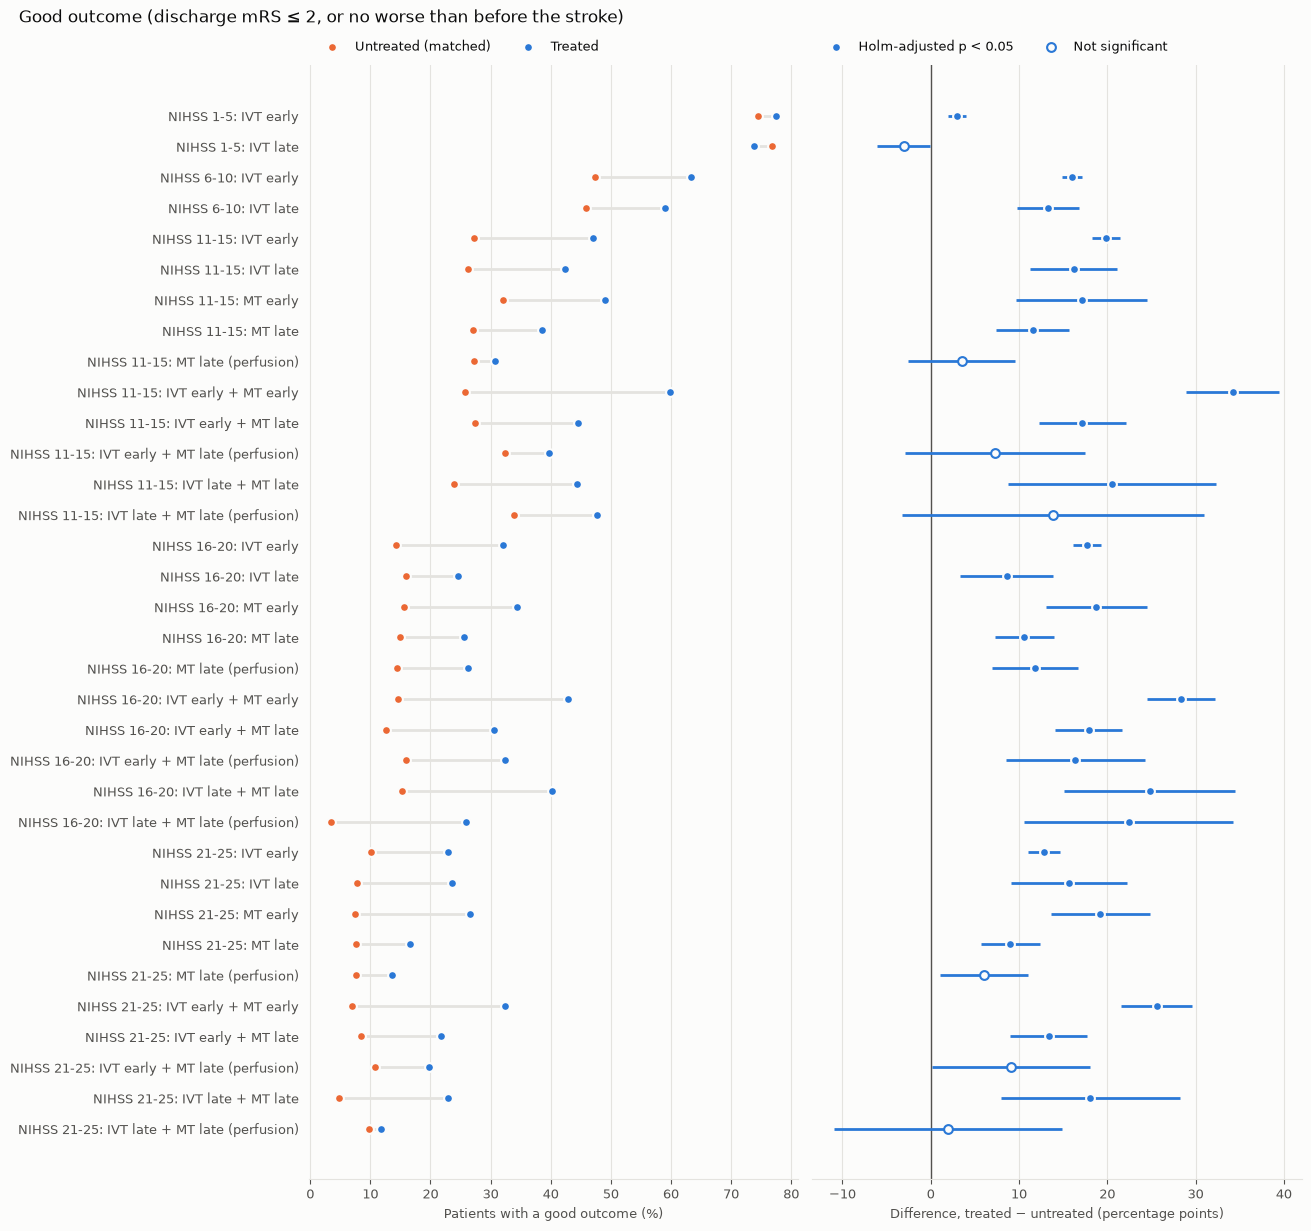

Saved table: ./output/all_ischaemic_stroke_target_trials_outcome_target_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_outcome_target_chart.png


,group_name,n_pairs,treated_events,treated_pct,untreated_events,untreated_pct,difference,ci_low,ci_high,matched_odds_ratio,or_ci_low,or_ci_high,test,p_value,p_value_holm
group_id,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12954,10034,77.458700,9647,74.471206,2.987494,1.975473,3.999516,1.188873,1.121035,1.260815,McNemar,8.23e-09,1.65e-07
2,NIHSS 1-5: IVT late,1440,1062,73.750000,1106,76.805556,-3.055556,-6.059247,-0.051864,0.834586,0.698378,0.997360,McNemar,0.0516,0.31
4,NIHSS 6-10: IVT early,13618,8632,63.386694,6447,47.341754,16.044941,14.918177,17.171704,2.017699,1.915976,2.124823,McNemar,4.01e-162,1.36e-160
5,NIHSS 6-10: IVT late,1478,873,59.066306,677,45.805142,13.261164,9.721426,16.800901,1.723247,1.483699,2.001471,McNemar,7.07e-13,1.84e-11
7,NIHSS 11-15: IVT early,6277,2952,47.028835,1705,27.162657,19.866178,18.258254,21.474102,2.509685,2.315232,2.720470,McNemar,1.77e-118,5.83e-117
8,NIHSS 11-15: IVT late,643,273,42.457232,169,26.283048,16.174184,11.263037,21.085330,2.209302,1.712483,2.850258,McNemar,5.65e-10,1.3e-08
10,NIHSS 11-15: MT early,281,138,49.110320,90,32.028470,17.081851,9.627730,24.535971,2.297297,1.561582,3.379634,McNemar,2.09e-05,0.000272
11,NIHSS 11-15: MT late,944,364,38.559322,255,27.012712,11.546610,7.441952,15.651269,1.741497,1.421789,2.133095,McNemar,7.45e-08,1.34e-06
12,NIHSS 11-15: MT late (perfusion),426,131,30.751174,116,27.230047,3.521127,-2.528323,9.570577,1.189873,0.882222,1.604810,McNemar,0.287,0.655


In [9]:
outcome_target_results = analyse_outcome(
    "outcome_target",
    "binary",
    title="Good outcome (discharge mRS ≤ 2, or no worse than before the stroke)",
    value_label="Patients with a good outcome (%)",
)

### In-hospital death (`death`)

Binary: death in hospital. Lower is better.

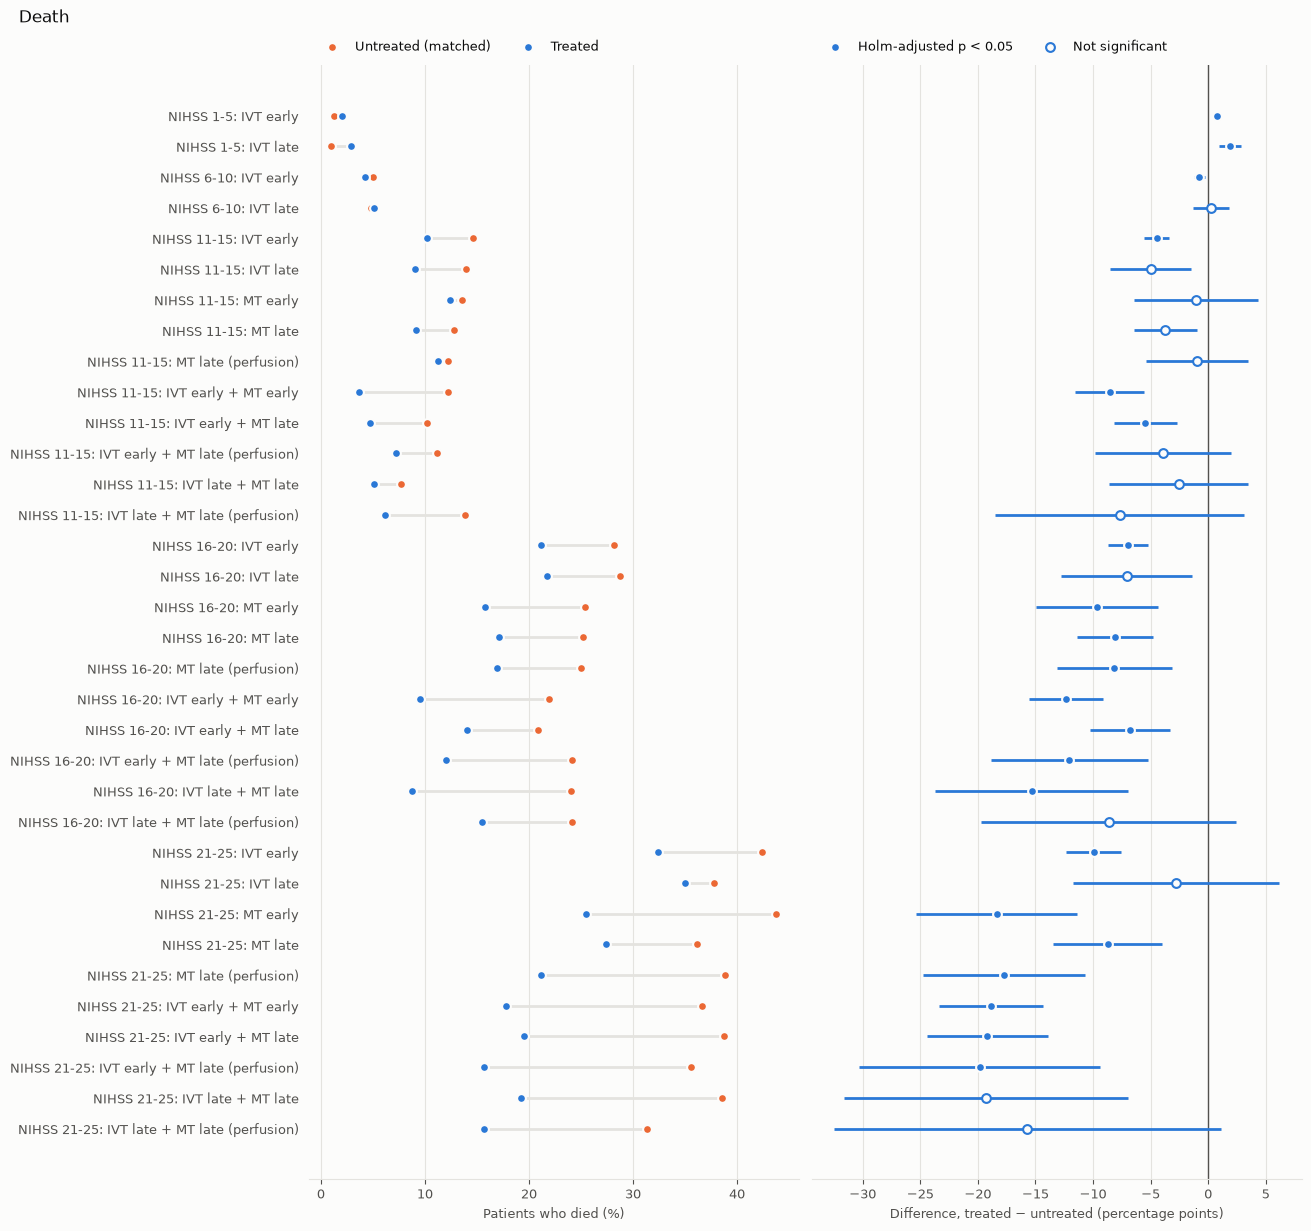

Saved table: ./output/all_ischaemic_stroke_target_trials_death_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_death_chart.png


,group_name,n_pairs,treated_events,treated_pct,untreated_events,untreated_pct,difference,ci_low,ci_high,matched_odds_ratio,or_ci_low,or_ci_high,test,p_value,p_value_holm
group_id,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12954,260,2.007102,160,1.235140,0.771962,0.465871,1.078054,1.645161,1.347451,2.008649,McNemar,1.01e-06,2.73e-05
2,NIHSS 1-5: IVT late,1440,41,2.847222,14,0.972222,1.875000,0.907473,2.842527,3.250000,1.701711,6.206988,McNemar,0.000272,0.00571
4,NIHSS 6-10: IVT early,13618,578,4.244382,683,5.015421,-0.771038,-1.266340,-0.275737,0.837209,0.746764,0.938608,McNemar,0.00252,0.0353
5,NIHSS 6-10: IVT late,1478,75,5.074425,71,4.803789,0.270636,-1.298916,1.840188,1.058824,0.760121,1.474906,McNemar,0.8,1
7,NIHSS 11-15: IVT early,6277,639,10.180022,920,14.656683,-4.476661,-5.578256,-3.375065,0.634590,0.566538,0.710817,McNemar,2.85e-15,9.39e-14
8,NIHSS 11-15: IVT late,643,58,9.020218,90,13.996890,-4.976672,-8.486932,-1.466412,0.614458,0.433553,0.870847,McNemar,0.00741,0.0889
10,NIHSS 11-15: MT early,281,35,12.455516,38,13.523132,-1.067616,-6.433385,4.298154,0.903226,0.541840,1.505641,McNemar,0.795,1
11,NIHSS 11-15: MT late,944,86,9.110169,121,12.817797,-3.707627,-6.429716,-0.985538,0.663462,0.489383,0.899461,McNemar,0.00974,0.107
12,NIHSS 11-15: MT late (perfusion),426,48,11.267606,52,12.206573,-0.938967,-5.356320,3.478385,0.916667,0.608909,1.379973,McNemar,0.754,1


In [10]:
death_results = analyse_outcome(
    "death",
    "binary",
    title="Death",
    value_label="Patients who died (%)",
)

### Discharge disability (`discharge_disability`)

Continuous: modified Rankin Scale at discharge (0-6). Lower is better. As mRS is ordinal, the Wilcoxon signed-rank test is the primary test.

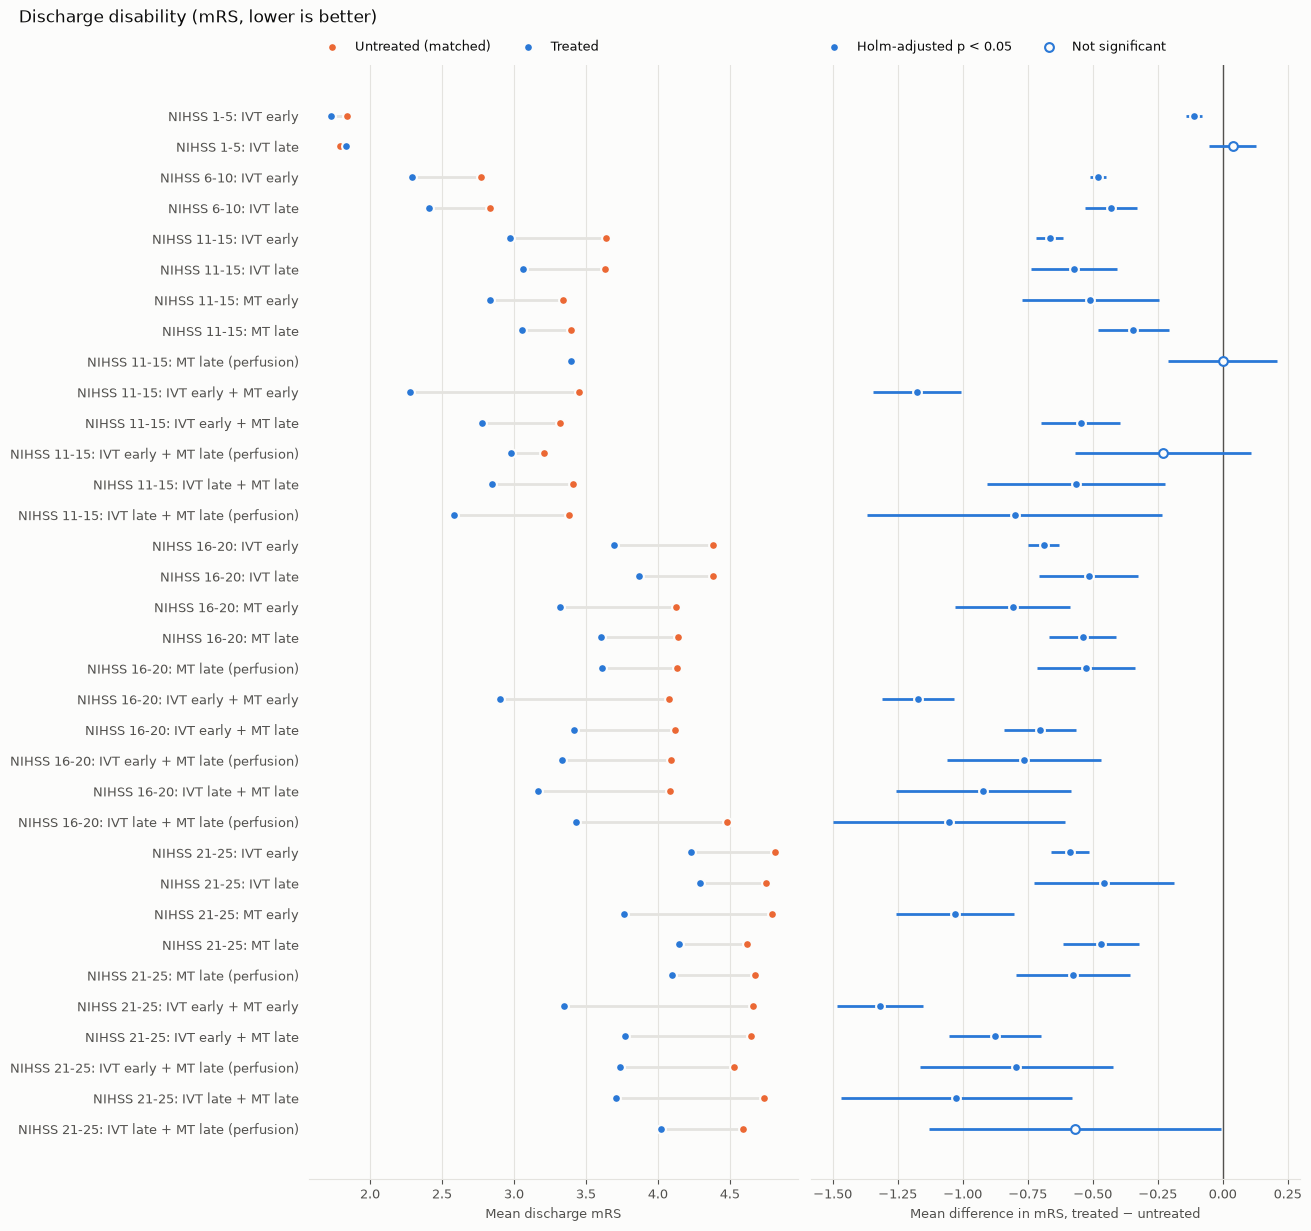

Saved table: ./output/all_ischaemic_stroke_target_trials_discharge_disability_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_discharge_disability_chart.png


,group_name,n_pairs,treated_mean,treated_sd,treated_median,treated_q1,treated_q3,untreated_mean,untreated_sd,untreated_median,untreated_q1,untreated_q3,difference,ci_low,ci_high,test,p_value,p_value_paired_t,p_value_holm
group_id,,,,,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12954,1.728810,1.370699,2.000000,1.000000,3.000000,1.838274,1.321136,2.000000,1.000000,3.000000,-0.109464,-0.139229,-0.079699,Wilcoxon signed-rank,1.81e-14,5.96e-13,3.99e-13
2,NIHSS 1-5: IVT late,1440,1.830556,1.430011,2.000000,1.000000,3.000000,1.792361,1.279256,2.000000,1.000000,3.000000,0.038194,-0.052083,0.128472,Wilcoxon signed-rank,0.574,0.407,1
4,NIHSS 6-10: IVT early,13618,2.293435,1.532096,2.000000,1.000000,3.000000,2.773094,1.470796,3.000000,2.000000,4.000000,-0.479659,-0.512000,-0.447319,Wilcoxon signed-rank,5.12e-177,2.47e-180,1.74e-175
5,NIHSS 6-10: IVT late,1478,2.407307,1.562683,2.000000,1.000000,3.000000,2.836265,1.427645,3.000000,2.000000,4.000000,-0.428958,-0.529016,-0.328900,Wilcoxon signed-rank,9.26e-17,9.58e-17,2.32e-15
7,NIHSS 11-15: IVT early,6277,2.973236,1.698681,3.000000,2.000000,4.000000,3.638522,1.532150,4.000000,3.000000,5.000000,-0.665286,-0.716770,-0.613802,Wilcoxon signed-rank,1.7e-127,7.04e-135,5.61e-126
8,NIHSS 11-15: IVT late,643,3.063764,1.658728,3.000000,2.000000,4.000000,3.636081,1.533044,4.000000,3.000000,5.000000,-0.572317,-0.736829,-0.407805,Wilcoxon signed-rank,2.46e-11,1.96e-11,4.68e-10
10,NIHSS 11-15: MT early,281,2.832740,1.699936,3.000000,2.000000,4.000000,3.341637,1.680989,3.000000,2.000000,4.000000,-0.508897,-0.772060,-0.245734,Wilcoxon signed-rank,8.44e-05,0.000173,0.000675
11,NIHSS 11-15: MT late,944,3.055085,1.576314,3.000000,2.000000,4.000000,3.399364,1.594809,3.000000,2.000000,4.000000,-0.344280,-0.480502,-0.208058,Wilcoxon signed-rank,3.63e-07,8.36e-07,5.08e-06
12,NIHSS 11-15: MT late (perfusion),426,3.394366,1.590965,4.000000,2.000000,4.000000,3.394366,1.559598,3.000000,2.000000,4.000000,0.000000,-0.210374,0.210374,Wilcoxon signed-rank,0.695,1,1


In [11]:
discharge_disability_results = analyse_outcome(
    "discharge_disability",
    "continuous",
    title="Discharge disability (mRS, lower is better)",
    value_label="Mean discharge mRS",
    diff_label="Mean difference in mRS, treated − untreated",
)

### Length of stay (`length_of_stay`)

Continuous, in days. Length of stay is right-skewed, so the Wilcoxon signed-rank test is the primary test. Patients who died in hospital are included.

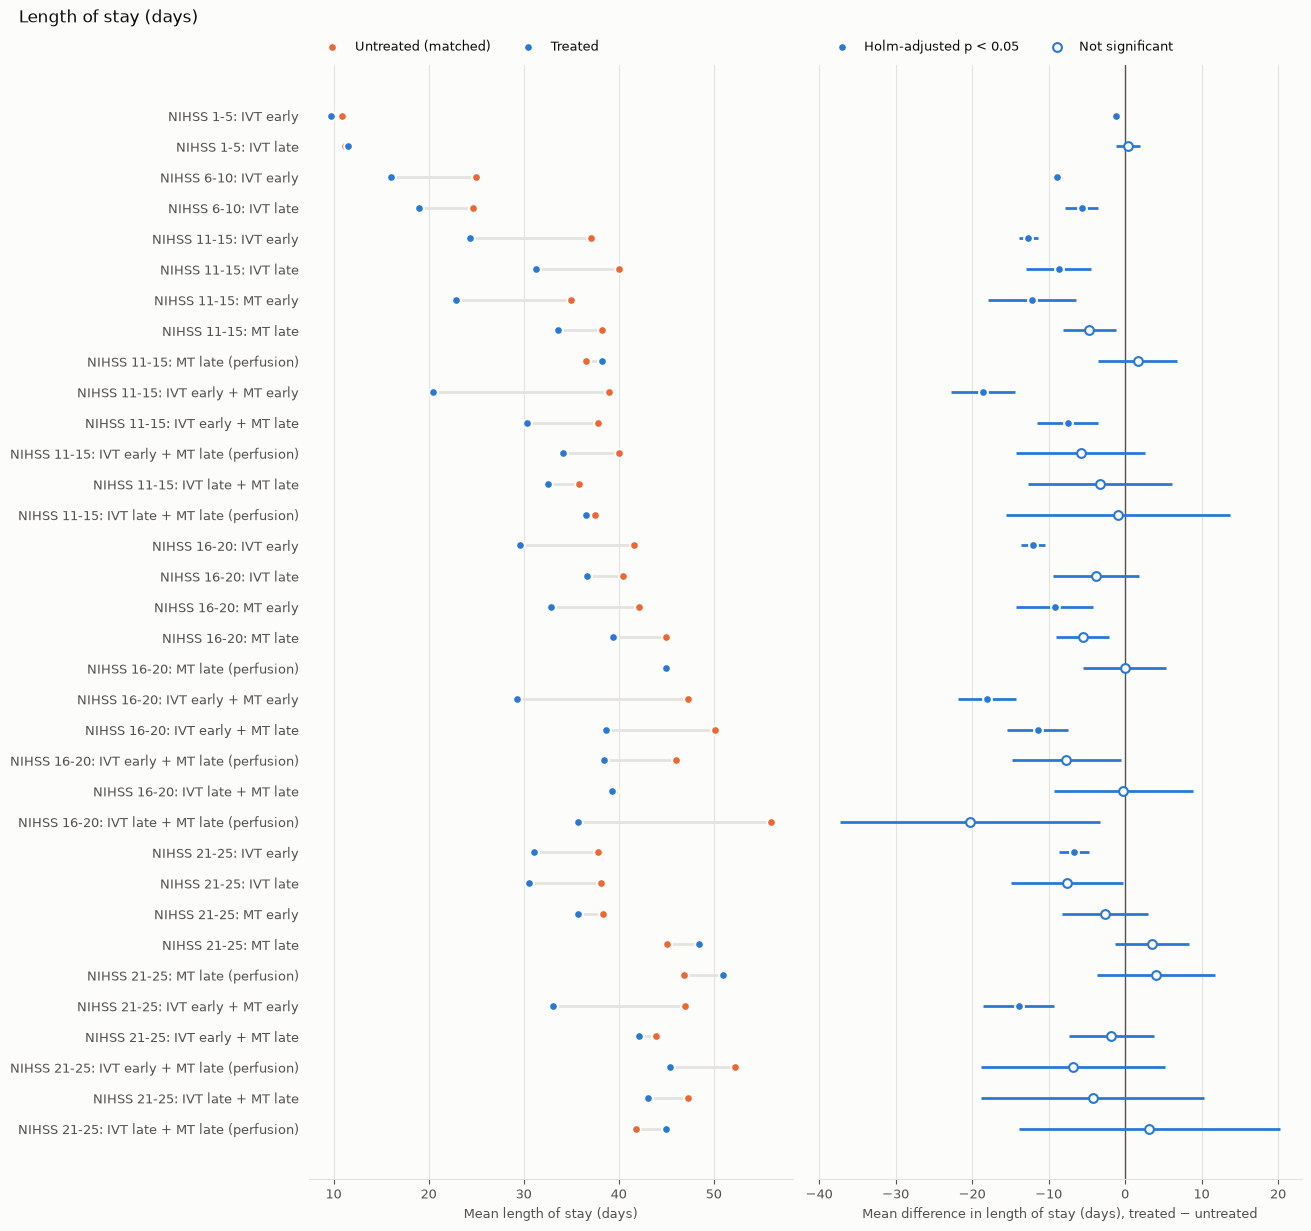

Saved table: ./output/all_ischaemic_stroke_target_trials_length_of_stay_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_length_of_stay_chart.png


,group_name,n_pairs,treated_mean,treated_sd,treated_median,treated_q1,treated_q3,untreated_mean,untreated_sd,untreated_median,untreated_q1,untreated_q3,difference,ci_low,ci_high,test,p_value,p_value_paired_t,p_value_holm
group_id,,,,,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12950,9.704093,19.329757,3.000000,2.000000,8.000000,10.902085,20.201254,4.000000,2.000000,10.000000,-1.197992,-1.672108,-0.723876,Wilcoxon signed-rank,1.69e-13,7.4e-07,4.72e-12
2,NIHSS 1-5: IVT late,1440,11.571528,22.986303,3.000000,2.000000,10.000000,11.166667,20.928250,3.000000,2.000000,10.000000,0.404861,-1.196265,2.005987,Wilcoxon signed-rank,0.492,0.62,1
4,NIHSS 6-10: IVT early,13616,16.077703,26.469084,5.000000,2.000000,18.000000,24.984504,31.552352,13.000000,5.000000,34.000000,-8.906801,-9.596155,-8.217447,Wilcoxon signed-rank,3.47e-238,2.57e-138,1.18e-236
5,NIHSS 6-10: IVT late,1478,19.006089,27.325602,7.000000,3.000000,24.000000,24.688769,31.680925,13.000000,4.000000,33.750000,-5.682679,-7.798075,-3.567284,Wilcoxon signed-rank,1.97e-11,1.57e-07,5.33e-10
7,NIHSS 11-15: IVT early,6274,24.400861,32.174274,11.000000,4.000000,34.000000,37.069015,37.783342,25.000000,9.000000,54.000000,-12.668154,-13.899192,-11.437116,Wilcoxon signed-rank,9.69e-113,9.74e-88,3.2e-111
8,NIHSS 11-15: IVT late,643,31.337481,38.407549,17.000000,5.000000,46.000000,40.020218,38.705026,28.000000,10.000000,58.500000,-8.682737,-12.950522,-4.414953,Wilcoxon signed-rank,1.18e-06,7.22e-05,2.83e-05
10,NIHSS 11-15: MT early,281,22.836299,29.972992,10.000000,5.000000,30.000000,35.028470,39.543727,21.000000,8.000000,53.000000,-12.192171,-17.941680,-6.442661,Wilcoxon signed-rank,3.06e-05,3.99e-05,0.000673
11,NIHSS 11-15: MT late,944,33.619703,37.412726,19.500000,6.000000,50.000000,38.268008,39.318360,25.000000,8.000000,58.000000,-4.648305,-8.060227,-1.236384,Wilcoxon signed-rank,0.0178,0.00763,0.321
12,NIHSS 11-15: MT late (perfusion),426,38.241784,39.734830,26.000000,8.000000,54.750000,36.582160,41.599820,23.000000,8.000000,54.750000,1.659624,-3.471129,6.790378,Wilcoxon signed-rank,0.291,0.525,1


In [12]:
length_of_stay_results = analyse_outcome(
    "length_of_stay",
    "continuous",
    title="Length of stay (days)",
    value_label="Mean length of stay (days)",
    diff_label="Mean difference in length of stay (days), treated − untreated",
)

### Discharge destination (`discharge_destination`)

Categorical. Destinations recorded as "missing" are treated as missing data, so those pairs are dropped.

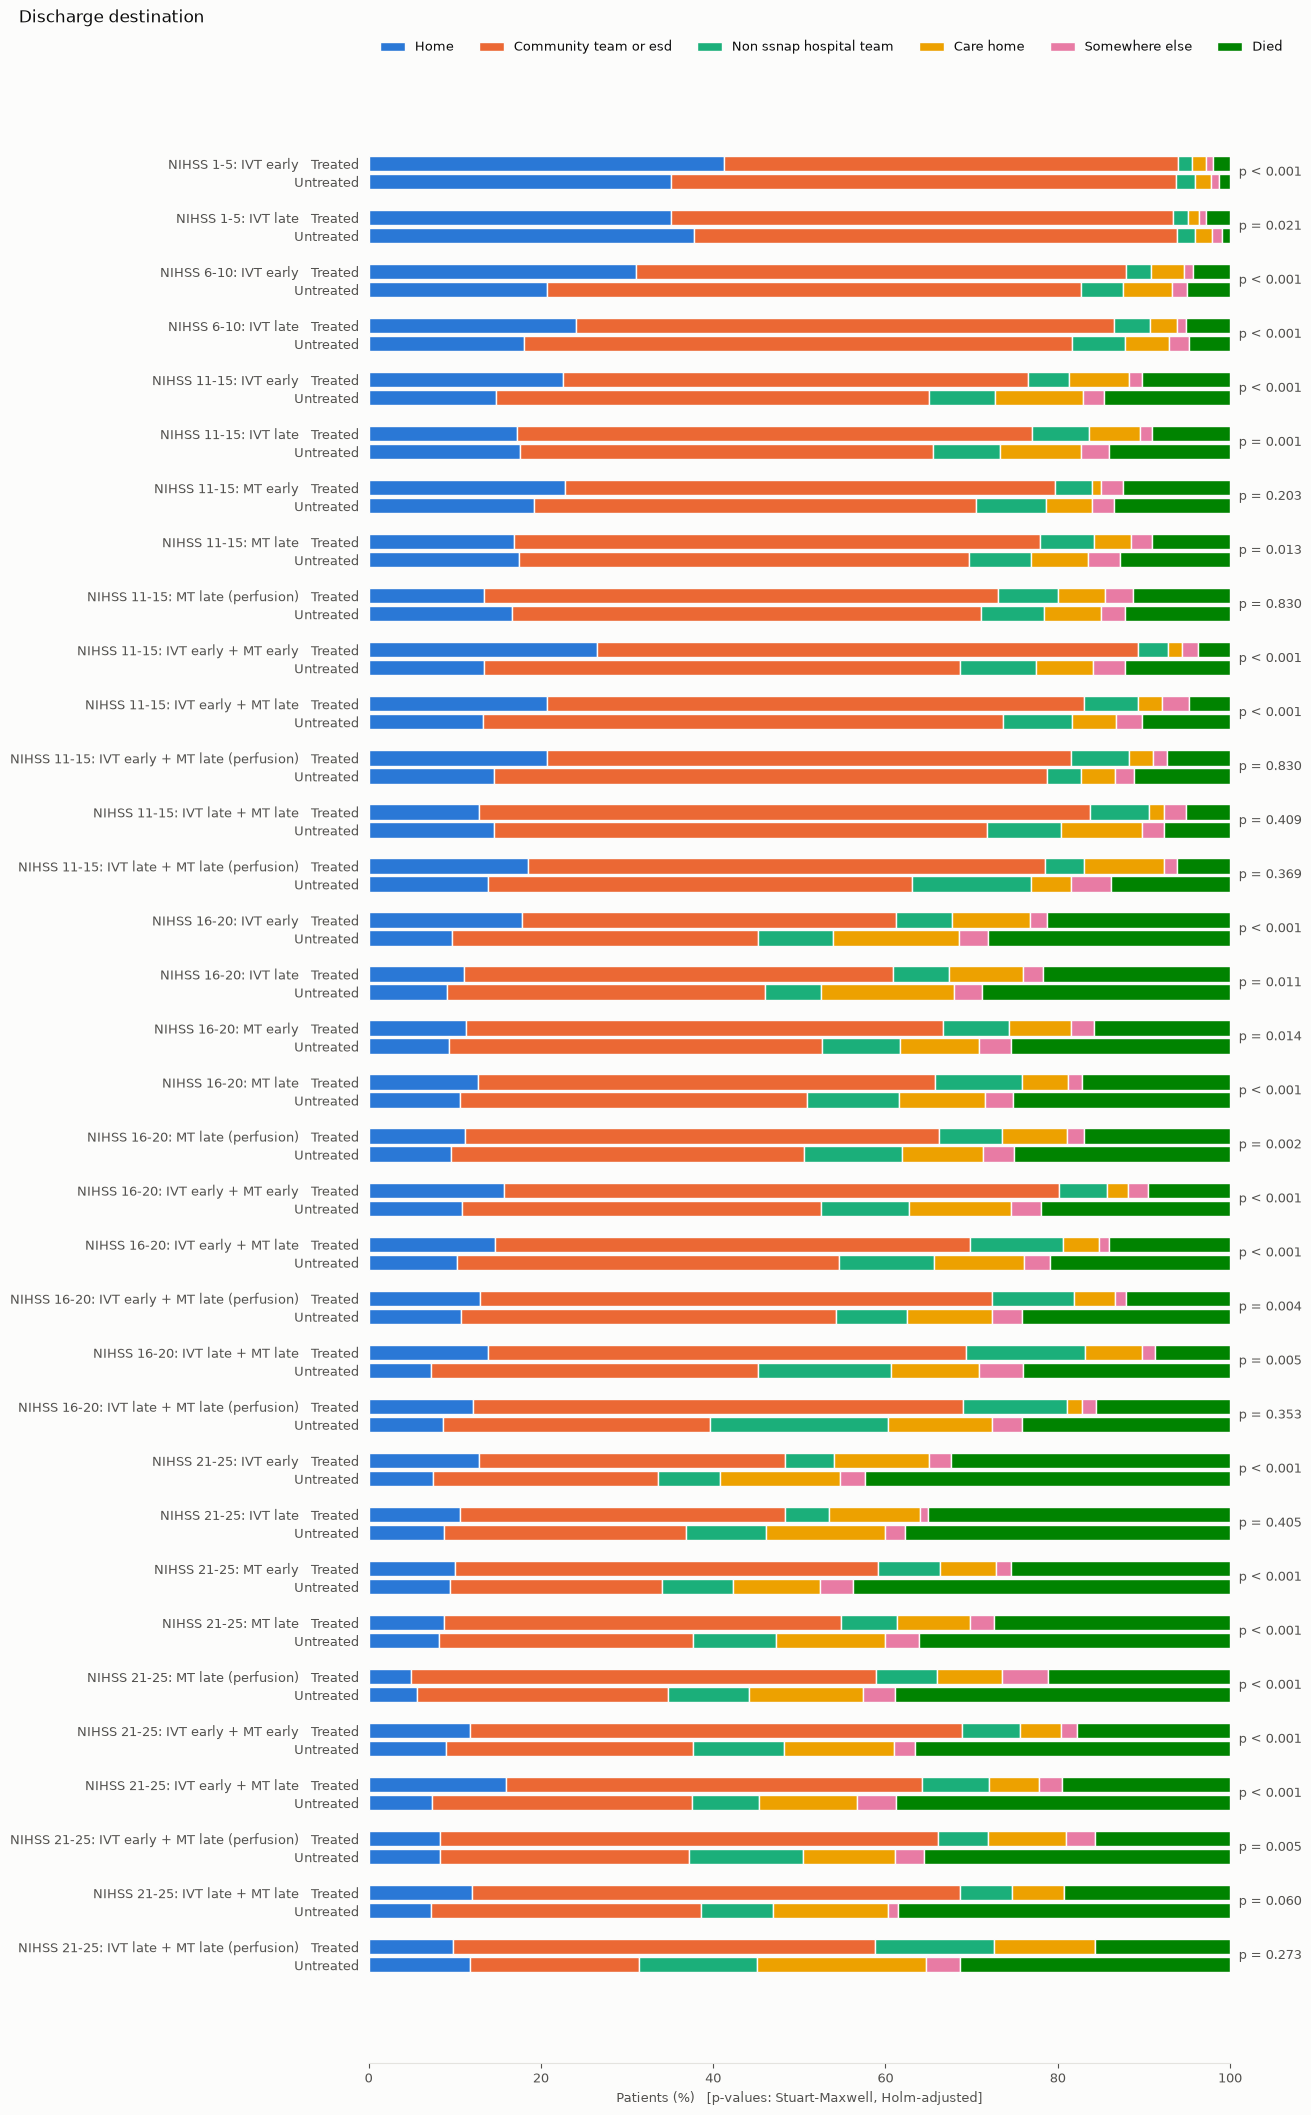

Saved table: ./output/all_ischaemic_stroke_target_trials_discharge_destination_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_discharge_destination_chart.png


,group_name,n_pairs,treated_pct_home,treated_pct_community_team_or_esd,treated_pct_non_ssnap_hospital_team,treated_pct_care_home,treated_pct_somewhere_else,treated_pct_died,untreated_pct_home,untreated_pct_community_team_or_esd,untreated_pct_non_ssnap_hospital_team,untreated_pct_care_home,untreated_pct_somewhere_else,untreated_pct_died,test,p_value,p_value_holm
group_id,,,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12952,41.260037,52.640519,1.683138,1.605930,0.802965,2.007412,35.137431,58.608709,2.177270,1.922483,0.918777,1.235330,Stuart-Maxwell,0,0
2,NIHSS 1-5: IVT late,1440,35.138889,58.263889,1.736111,1.250000,0.763889,2.847222,37.777778,56.041667,2.152778,1.944444,1.111111,0.972222,Stuart-Maxwell,0.0021,0.021
4,NIHSS 6-10: IVT early,13617,31.012705,56.884776,2.966880,3.818756,1.072189,4.244694,20.724095,61.974003,4.817508,5.728134,1.747815,5.008445,Stuart-Maxwell,0,0
5,NIHSS 6-10: IVT late,1478,24.086604,62.449256,4.127199,3.179973,1.082544,5.074425,17.997294,63.599459,6.156969,5.209743,2.232747,4.803789,Stuart-Maxwell,3.26e-06,6.53e-05
7,NIHSS 11-15: IVT early,6277,22.542616,54.038553,4.731560,6.945993,1.561255,10.180022,14.831926,50.183209,7.678827,10.259678,2.389677,14.656683,Stuart-Maxwell,0,0
8,NIHSS 11-15: IVT late,643,17.262830,59.720062,6.687403,5.909798,1.399689,9.020218,17.573872,47.900467,7.776050,9.486781,3.265941,13.996890,Stuart-Maxwell,7.48e-05,0.00135
10,NIHSS 11-15: MT early,281,22.775801,56.939502,4.270463,1.067616,2.491103,12.455516,19.217082,51.245552,8.185053,5.338078,2.491103,13.523132,Stuart-Maxwell,0.0254,0.203
11,NIHSS 11-15: MT late,944,16.843220,61.122881,6.250000,4.343220,2.330508,9.110169,17.478814,52.224576,7.203390,6.567797,3.707627,12.817797,Stuart-Maxwell,0.0011,0.0133
12,NIHSS 11-15: MT late (perfusion),426,13.380282,59.624413,7.042254,5.399061,3.286385,11.267606,16.666667,54.460094,7.276995,6.572770,2.816901,12.206573,Stuart-Maxwell,0.625,0.83


In [13]:
discharge_destination_results = analyse_outcome(
    "discharge_destination",
    "categorical",
    title="Discharge destination",
    category_order=[
        "home",
        "community_team_or_esd",
        "non_ssnap_hospital_team",
        "care_home",
        "somewhere_else",
        "died",
    ],
)